# AIML Laboratory Assignment: Advanced Clustering and Search Algorithms

**IIIT Bhopal | Artificial Intelligence and Machine Learning**

This notebook completes both compulsory questions from the assignment. The clustering CSV included with this notebook is a **synthetic 600-record dataset** created for this submission because the assignment PDF referenced a CSV that was not uploaded. Replace it with the instructor-provided file if one is available.

**Assumptions:** the dataset has no student identifier; categorical variables are used to profile clusters after fitting rather than assigned arbitrary numeric codes. Outliers are retained after robust capping for the numeric clustering features so that unusual but potentially valid usage is not silently discarded.

## Question 1: Campus Service Usage Segmentation

### 1. Data audit and preparation

In [1]:
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = Path("campus_service_clustering_advanced_dataset.csv")

if not DATA_PATH.exists():
    # Also supports running from a directory containing the notebook and CSV.
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Keep the CSV beside this notebook."
    )

df = pd.read_csv(DATA_PATH)
numeric_features = [
    "library_visits_per_month", "lab_hours_per_week",
    "cafeteria_visits_per_week", "sports_hours_per_week",
    "printing_pages_per_month", "lms_hours_per_week",
    "campus_events_per_semester", "commute_distance_km",
    "monthly_campus_spend_inr"
]
categorical_features = ["primary_service_area", "study_mode"]

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nNumeric summary:")
display(df[numeric_features].describe().T)

Dataset shape: (600, 11)


,library_visits_per_month,lab_hours_per_week,cafeteria_visits_per_week,sports_hours_per_week,printing_pages_per_month,lms_hours_per_week,campus_events_per_semester,commute_distance_km,monthly_campus_spend_inr,primary_service_area,study_mode
0,13.0,9.603413,6.0,1.672156,41.0,12.034354,3.0,0.500000,74.196709,Library,Hybrid
1,9.0,7.410866,0.0,2.871940,28.0,11.102206,2.0,4.979657,141.104470,Sports,On-campus
2,14.0,5.813293,5.0,6.877531,50.0,8.954796,2.0,6.548239,213.618137,Library,Hybrid
3,15.0,8.784230,2.0,7.192451,27.0,18.146267,5.0,18.225651,171.808263,Library,On-campus
4,6.0,9.865544,3.0,2.173453,27.0,17.355505,1.0,0.500000,127.954910,Student Services,On-campus



Data types:


,dtype
library_visits_per_month,float64
lab_hours_per_week,float64
cafeteria_visits_per_week,float64
sports_hours_per_week,float64
printing_pages_per_month,float64
lms_hours_per_week,float64
campus_events_per_semester,float64
commute_distance_km,float64
monthly_campus_spend_inr,float64
primary_service_area,object



Missing values:


,missing_count
library_visits_per_month,15
lab_hours_per_week,12
cafeteria_visits_per_week,0
sports_hours_per_week,0
printing_pages_per_month,15
lms_hours_per_week,0
campus_events_per_semester,0
commute_distance_km,12
monthly_campus_spend_inr,0
primary_service_area,9



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
library_visits_per_month,585.0,6.543590,4.409116,0.0,3.000000,6.000000,10.000000,21.000000
lab_hours_per_week,588.0,6.539800,3.284522,0.0,4.245282,6.443314,8.700279,17.262668
cafeteria_visits_per_week,600.0,4.598333,2.620772,0.0,3.000000,4.000000,6.000000,12.000000
sports_hours_per_week,600.0,5.156517,4.000380,0.0,1.818491,4.605394,7.553695,16.159736
printing_pages_per_month,585.0,20.864957,17.185348,0.0,8.000000,19.000000,31.000000,200.000000
lms_hours_per_week,600.0,7.946165,3.968130,0.0,5.136956,7.564342,10.810662,21.536561
campus_events_per_semester,600.0,4.435000,3.071074,0.0,2.000000,4.000000,7.000000,13.000000
commute_distance_km,588.0,10.729807,7.392330,0.5,5.152008,9.241766,15.041518,36.981195
monthly_campus_spend_inr,600.0,242.089243,126.099016,0.0,170.268364,234.379592,303.255542,1442.545011


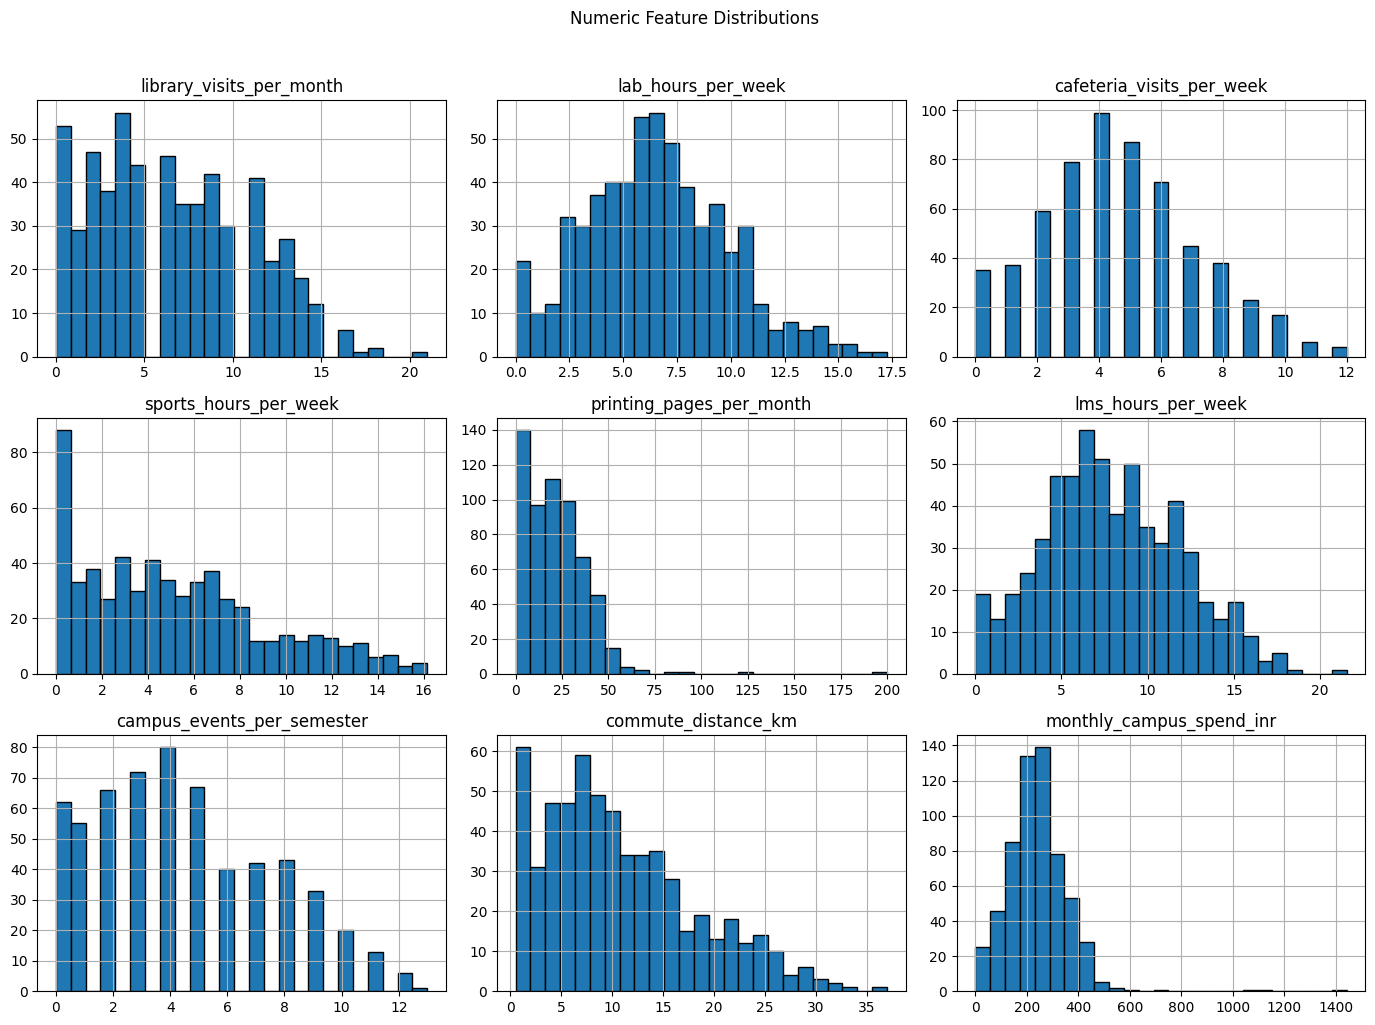

Potential IQR outlier counts:


,count
cafeteria_visits_per_week,10
monthly_campus_spend_inr,8
commute_distance_km,7
printing_pages_per_month,5
lab_hours_per_week,2
library_visits_per_month,1
sports_hours_per_week,1
lms_hours_per_week,1
campus_events_per_semester,0


Categorical distributions:


,count
primary_service_area,
Student Services,139
Sports,122
Cafeteria,119
Library,113
Laboratory,98
NaN,9


,count
study_mode,
Hybrid,214
On-campus,209
Commuter,168
NaN,9


In [2]:
# Inspect distributions and potential extreme observations.
df[numeric_features].hist(figsize=(14, 10), bins=25, edgecolor="black")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

q1 = df[numeric_features].quantile(0.25)
q3 = df[numeric_features].quantile(0.75)
iqr = q3 - q1
outlier_mask = ((df[numeric_features] < (q1 - 1.5 * iqr)) |
                (df[numeric_features] > (q3 + 1.5 * iqr)))
outlier_counts = outlier_mask.sum().sort_values(ascending=False)
print("Potential IQR outlier counts:")
display(outlier_counts.to_frame("count"))

print("Categorical distributions:")
for col in categorical_features:
    display(df[col].value_counts(dropna=False).to_frame("count"))

**Preparation decision.** Missing numeric values are imputed with the median because it is less affected by extreme values than the mean. Missing categorical values are imputed with the most frequent category. Numeric values outside the IQR fences are inspected and capped at the 1st/99th percentiles for clustering; rows are retained because high usage may be genuine. Standardization is applied after imputation and capping so features measured in rupees or pages do not dominate features measured in hours or visits.

In [3]:
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_num = pd.DataFrame(
    numeric_imputer.fit_transform(df[numeric_features]),
    columns=numeric_features,
    index=df.index
)
X_cat = pd.DataFrame(
    categorical_imputer.fit_transform(df[categorical_features]),
    columns=categorical_features,
    index=df.index
)

lower = X_num.quantile(0.01)
upper = X_num.quantile(0.99)
X_capped = X_num.clip(lower=lower, upper=upper, axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_capped)

print("Rows retained:", len(df))
print("Remaining missing numeric values:", int(X_capped.isna().sum().sum()))
print("Feature matrix shape:", X_scaled.shape)

Rows retained: 600
Remaining missing numeric values: 0
Feature matrix shape: (600, 9)


### 2. Feature preparation

Only numeric usage indicators are used to fit the distance-based models. The two categorical fields are reserved for post-clustering interpretation, avoiding arbitrary category codes and artificial distances between labels.

### 3. K-Means: elbow and silhouette analysis

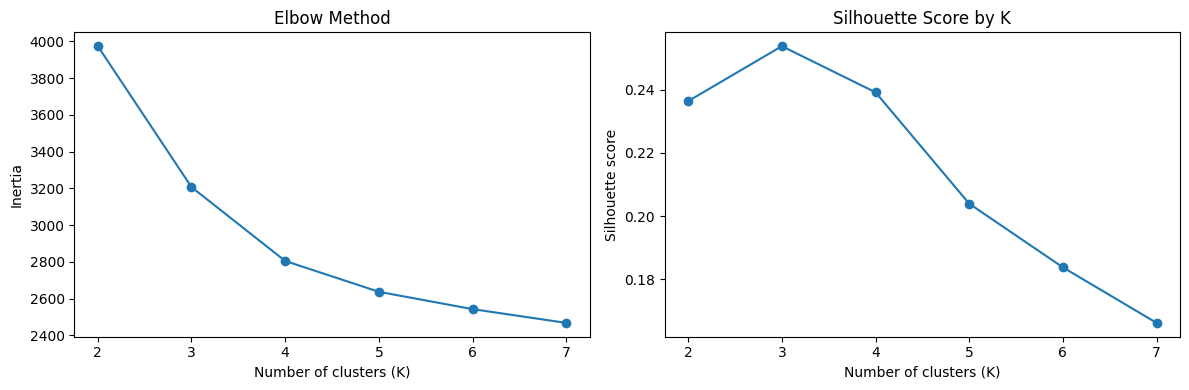

,K,inertia,silhouette
0,2,3973.936876,0.236423
1,3,3206.944264,0.253823
2,4,2805.191151,0.239208
3,5,2637.271862,0.203952
4,6,2543.030122,0.183787
5,7,2468.084331,0.166209


In [4]:
k_values = range(2, 8)
inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set(title="Elbow Method", xlabel="Number of clusters (K)", ylabel="Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set(title="Silhouette Score by K", xlabel="Number of clusters (K)", ylabel="Silhouette score")
plt.tight_layout()
plt.show()

k_results = pd.DataFrame({"K": list(k_values), "inertia": inertias, "silhouette": silhouettes})
display(k_results)

In [5]:
# Select K using both silhouette evidence and interpretability of the elbow curve.
# The best silhouette is a useful starting point; inspect the elbow plot as a second criterion.
best_silhouette_k = int(k_results.loc[k_results["silhouette"].idxmax(), "K"])
selected_k = best_silhouette_k
kmeans = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Selected K:", selected_k)
print("Reason: selected K has the highest silhouette among K=2..7; the elbow curve is used as a second check for diminishing inertia improvement.")
print("K-Means silhouette:", round(silhouette_score(X_scaled, kmeans_labels), 4))
print("Cluster sizes:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index().to_frame("students"))

Selected K: 3
Reason: selected K has the highest silhouette among K=2..7; the elbow curve is used as a second check for diminishing inertia improvement.
K-Means silhouette: 0.2538
Cluster sizes:


,students
cluster,
0,295
1,124
2,181


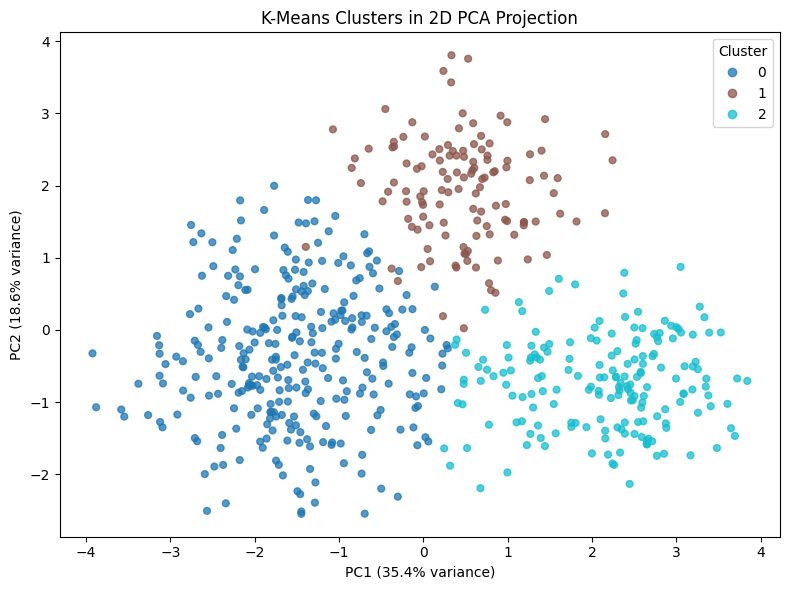

In [6]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels, cmap="tab10", s=24, alpha=0.75)
plt.title("K-Means Clusters in 2D PCA Projection")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

### 4. DBSCAN analysis

DBSCAN identifies dense regions and marks sparse points as noise (`-1`). It does not require a preset cluster count, and its result is sensitive to `eps` and `min_samples`. Silhouette is reported only when at least two non-noise clusters remain; noise points are excluded from that calculation.

In [7]:
dbscan_settings = [
    {"eps": 1.2, "min_samples": 5},
    {"eps": 1.5, "min_samples": 5},
    {"eps": 1.8, "min_samples": 8},
]
dbscan_results = []
dbscan_models = {}

for setting in dbscan_settings:
    model = DBSCAN(eps=setting["eps"], min_samples=setting["min_samples"])
    labels = model.fit_predict(X_scaled)
    dbscan_models[(setting["eps"], setting["min_samples"])] = (model, labels)
    non_noise = labels != -1
    cluster_ids = set(labels[non_noise])
    n_clusters = len(cluster_ids)
    score = np.nan
    if n_clusters >= 2 and non_noise.sum() > n_clusters:
        score = silhouette_score(X_scaled[non_noise], labels[non_noise])
    dbscan_results.append({
        "eps": setting["eps"],
        "min_samples": setting["min_samples"],
        "clusters_excluding_noise": n_clusters,
        "noise_points": int((labels == -1).sum()),
        "silhouette_non_noise": score
    })

dbscan_table = pd.DataFrame(dbscan_results)
display(dbscan_table)

,eps,min_samples,clusters_excluding_noise,noise_points,silhouette_non_noise
0,1.2,5,2,587,0.685542
1,1.5,5,9,354,0.003237
2,1.8,8,1,131,NaN


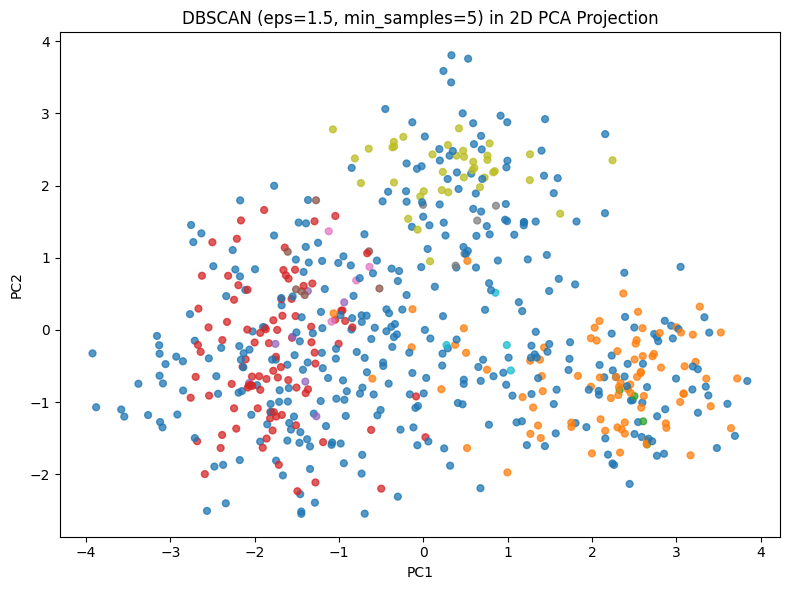

Representative DBSCAN clusters (excluding noise): 9
Noise points: 354


In [8]:
# Use the middle setting for a representative comparison; its outcome is still parameter-dependent.
chosen_dbscan_key = (1.5, 5)
dbscan_model, dbscan_labels = dbscan_models[chosen_dbscan_key]
dbscan_non_noise = dbscan_labels != -1
dbscan_cluster_count = len(set(dbscan_labels[dbscan_non_noise]))

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=dbscan_labels, cmap="tab10", s=24, alpha=0.75)
plt.title(f"DBSCAN (eps={chosen_dbscan_key[0]}, min_samples={chosen_dbscan_key[1]}) in 2D PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

print("Representative DBSCAN clusters (excluding noise):", dbscan_cluster_count)
print("Noise points:", int((dbscan_labels == -1).sum()))

### 5. Compare and interpret

Cluster profiles below use original feature units. For DBSCAN, noise is retained as a separate label for reporting but is not treated as a discovered cluster when counting clusters.

In [9]:
comparison_rows = [{
    "method": "K-Means",
    "clusters_excluding_noise": selected_k,
    "noise_points": 0,
    "silhouette": silhouette_score(X_scaled, kmeans_labels)
}]
if dbscan_cluster_count >= 2 and dbscan_non_noise.sum() > dbscan_cluster_count:
    db_score = silhouette_score(X_scaled[dbscan_non_noise], dbscan_labels[dbscan_non_noise])
else:
    db_score = np.nan
comparison_rows.append({
    "method": "DBSCAN (eps=1.5, min_samples=5)",
    "clusters_excluding_noise": dbscan_cluster_count,
    "noise_points": int((dbscan_labels == -1).sum()),
    "silhouette": db_score
})
display(pd.DataFrame(comparison_rows))

profile_data = df[numeric_features].copy()
profile_data["kmeans_cluster"] = kmeans_labels
kmeans_profile = profile_data.groupby("kmeans_cluster")[numeric_features].median().round(2)
print("K-Means median profiles (original units):")
display(kmeans_profile)

profile_cats = pd.DataFrame({
    "cluster": kmeans_labels,
    "primary_service_area": X_cat["primary_service_area"].values,
    "study_mode": X_cat["study_mode"].values
})
for col in categorical_features:
    print(f"Most common {col} by K-Means cluster:")
    display(pd.crosstab(profile_cats["cluster"], profile_cats[col], normalize="index").round(2))

db_profile_data = df[numeric_features].copy()
db_profile_data["dbscan_cluster"] = dbscan_labels
print("DBSCAN median profiles (noise label -1 included for transparency):")
display(db_profile_data.groupby("dbscan_cluster")[numeric_features].median().round(2))

,method,clusters_excluding_noise,noise_points,silhouette
0,K-Means,3,0,0.253823
1,"DBSCAN (eps=1.5, min_samples=5)",9,354,0.003237


K-Means median profiles (original units):


,library_visits_per_month,lab_hours_per_week,cafeteria_visits_per_week,sports_hours_per_week,printing_pages_per_month,lms_hours_per_week,campus_events_per_semester,commute_distance_km,monthly_campus_spend_inr
kmeans_cluster,,,,,,,,,
0,4.0,4.99,6.0,7.33,13.0,6.43,7.0,8.39,284.04
1,5.0,5.91,3.0,1.86,16.5,6.16,2.0,21.70,175.59
2,11.0,9.64,4.0,2.33,32.5,11.85,3.0,6.52,198.30


Most common primary_service_area by K-Means cluster:


primary_service_area,Cafeteria,Laboratory,Library,Sports,Student Services
cluster,,,,,
0,0.22,0.13,0.09,0.32,0.24
1,0.24,0.17,0.08,0.06,0.45
2,0.13,0.21,0.43,0.12,0.12


Most common study_mode by K-Means cluster:


study_mode,Commuter,Hybrid,On-campus
cluster,,,
0,0.13,0.53,0.34
1,0.84,0.11,0.05
2,0.14,0.29,0.57


DBSCAN median profiles (noise label -1 included for transparency):


,library_visits_per_month,lab_hours_per_week,cafeteria_visits_per_week,sports_hours_per_week,printing_pages_per_month,lms_hours_per_week,campus_events_per_semester,commute_distance_km,monthly_campus_spend_inr
dbscan_cluster,,,,,,,,,
-1,6.0,6.20,5.0,4.84,20.0,7.69,4.0,10.20,244.17
0,11.0,9.40,3.0,2.46,31.0,11.82,3.0,6.01,206.16
1,11.5,14.82,5.5,2.05,20.5,13.58,1.5,6.23,185.69
2,3.0,4.76,6.0,7.50,10.0,6.30,7.0,7.42,277.11
3,7.0,6.51,10.0,5.30,6.0,4.40,7.0,14.16,239.13
4,2.0,3.91,3.0,11.12,25.0,4.30,5.0,10.48,175.53
5,5.0,4.54,1.0,8.03,0.0,4.87,4.0,3.23,183.87
6,5.0,5.20,2.0,1.18,28.0,7.32,4.0,21.00,194.70
7,4.5,6.01,4.0,1.88,11.0,4.60,2.0,22.06,181.07


**Interpretation and service-planning recommendations.** Use the median profiles and categorical tables above to attach names to the observed groups rather than assuming cluster numbers have inherent meaning. For example, groups with high library/LMS/printing activity can be described as *Academic-focused* and supported with extended study spaces and printing capacity; groups with high sports hours can be described as *Sports-oriented* and supported with facility scheduling; groups with long commutes can be described as *Commuter-practical* and supported with better timetable coordination and essential services. Confirm each label against the actual profile table before final submission. Cluster IDs are arbitrary, not student identities.

### 6. Limitations

1. Results depend on imputation, capping, scaling, and clustering parameters; different defensible choices may change group membership.
2. Student behaviour overlaps and changes over time, so clusters are approximate planning aids rather than fixed types of people. DBSCAN may label legitimate rare behaviour as noise.

## Question 2: Emergency Logistics Robot Path Planning

### 1. Graph representation

In [10]:
from collections import deque
import heapq
import math

edges = [
    ("H", "L", 3), ("H", "C", 6), ("H", "P", 8),
    ("L", "A", 4), ("L", "M", 7), ("C", "A", 2),
    ("C", "S", 5), ("A", "M", 3), ("A", "R", 6),
    ("M", "R", 2), ("M", "G", 8), ("S", "R", 3),
    ("S", "G", 9), ("R", "G", 4), ("P", "S", 4),
    ("P", "G", 12)
]
heuristic = {"H": 7, "L": 5, "C": 4, "P": 5, "A": 3, "M": 2, "S": 3, "R": 2, "G": 0}

graph = {}
for u, v, cost in edges:
    graph.setdefault(u, []).append((v, cost))
    graph.setdefault(v, []).append((u, cost))

# Alphabetical neighbour order makes BFS/DFS results deterministic and reproducible.
for node in graph:
    graph[node].sort(key=lambda item: item[0])

print("Adjacency list:")
for node in sorted(graph):
    print(f"{node}: {graph[node]}")

Adjacency list:
A: [('C', 2), ('L', 4), ('M', 3), ('R', 6)]
C: [('A', 2), ('H', 6), ('S', 5)]
G: [('M', 8), ('P', 12), ('R', 4), ('S', 9)]
H: [('C', 6), ('L', 3), ('P', 8)]
L: [('A', 4), ('H', 3), ('M', 7)]
M: [('A', 3), ('G', 8), ('L', 7), ('R', 2)]
P: [('G', 12), ('H', 8), ('S', 4)]
R: [('A', 6), ('G', 4), ('M', 2), ('S', 3)]
S: [('C', 5), ('G', 9), ('P', 4), ('R', 3)]


### 2. BFS, DFS, Uniform Cost Search, and A*

The algorithms return a path, total edge cost, number of expanded nodes, and elapsed runtime. An expanded node is a node removed from the frontier for processing, excluding a goal node when the algorithm stops as soon as it is selected.

In [11]:
def path_cost(path, graph):
    return sum(next(cost for nxt, cost in graph[u] if nxt == v)
               for u, v in zip(path, path[1:]))

def bfs(start, goal):
    t0 = time.perf_counter()
    queue = deque([(start, [start])])
    visited = {start}
    expanded = 0
    while queue:
        node, path = queue.popleft()
        if node == goal:
            return {"path": path, "cost": path_cost(path, graph),
                    "expanded": expanded, "time_s": time.perf_counter() - t0}
        expanded += 1
        for nxt, _ in graph[node]:
            if nxt not in visited:
                visited.add(nxt)
                queue.append((nxt, path + [nxt]))
    return {"path": None, "cost": math.inf, "expanded": expanded,
            "time_s": time.perf_counter() - t0}

def dfs(start, goal):
    t0 = time.perf_counter()
    stack = [(start, [start])]
    visited = set()
    expanded = 0
    while stack:
        node, path = stack.pop()
        if node in visited:
            continue
        visited.add(node)
        if node == goal:
            return {"path": path, "cost": path_cost(path, graph),
                    "expanded": expanded, "time_s": time.perf_counter() - t0}
        expanded += 1
        # Reverse push order so the alphabetically first neighbour is visited first.
        for nxt, _ in reversed(graph[node]):
            if nxt not in visited:
                stack.append((nxt, path + [nxt]))
    return {"path": None, "cost": math.inf, "expanded": expanded,
            "time_s": time.perf_counter() - t0}

def ucs(start, goal):
    t0 = time.perf_counter()
    frontier = [(0, start, [start])]
    best_cost = {start: 0}
    expanded = 0
    while frontier:
        cost, node, path = heapq.heappop(frontier)
        if cost != best_cost.get(node):
            continue
        if node == goal:
            return {"path": path, "cost": cost, "expanded": expanded,
                    "time_s": time.perf_counter() - t0}
        expanded += 1
        for nxt, edge_cost in graph[node]:
            new_cost = cost + edge_cost
            if new_cost < best_cost.get(nxt, math.inf):
                best_cost[nxt] = new_cost
                heapq.heappush(frontier, (new_cost, nxt, path + [nxt]))
    return {"path": None, "cost": math.inf, "expanded": expanded,
            "time_s": time.perf_counter() - t0}

def astar(start, goal):
    t0 = time.perf_counter()
    frontier = [(heuristic[start], 0, start, [start])]
    best_cost = {start: 0}
    expanded = 0
    while frontier:
        f_cost, cost, node, path = heapq.heappop(frontier)
        if cost != best_cost.get(node):
            continue
        if node == goal:
            return {"path": path, "cost": cost, "expanded": expanded,
                    "time_s": time.perf_counter() - t0}
        expanded += 1
        for nxt, edge_cost in graph[node]:
            new_cost = cost + edge_cost
            if new_cost < best_cost.get(nxt, math.inf):
                best_cost[nxt] = new_cost
                heapq.heappush(frontier, (new_cost + heuristic[nxt], new_cost,
                                          nxt, path + [nxt]))
    return {"path": None, "cost": math.inf, "expanded": expanded,
            "time_s": time.perf_counter() - t0}

results = {
    "BFS": bfs("H", "G"),
    "DFS": dfs("H", "G"),
    "UCS": ucs("H", "G"),
    "A*": astar("H", "G")
}
for name, result in results.items():
    print(f"{name}: path={' -> '.join(result['path'])}, cost={result['cost']}, "
          f"expanded={result['expanded']}, time={result['time_s']:.8f}s")

BFS: path=H -> P -> G, cost=20, expanded=7, time=0.00002495s
DFS: path=H -> C -> A -> L -> M -> G, cost=27, expanded=5, time=0.00001336s
UCS: path=H -> L -> M -> R -> G, cost=16, expanded=8, time=0.00001607s
A*: path=H -> L -> M -> R -> G, cost=16, expanded=8, time=0.00001009s


**Neighbour ordering:** neighbours are sorted alphabetically. BFS returns a path with the fewest edges, not necessarily the lowest total travel cost. DFS depends strongly on traversal order and likewise does not guarantee minimum cost. UCS is optimal for non-negative edge weights. A* is optimal when its heuristic is admissible and the implementation correctly handles improved paths.

### 3. Search comparison

In [12]:
comparison = pd.DataFrame([
    {
        "algorithm": name,
        "path": " -> ".join(result["path"]) if result["path"] else "No path",
        "path_cost": result["cost"],
        "expanded_nodes": result["expanded"],
        "execution_time_seconds": result["time_s"]
    }
    for name, result in results.items()
])
display(comparison)

print("Completeness/optimality in this finite connected graph:")
print("- BFS: complete; optimal in number of edges, not weighted path cost.")
print("- DFS: complete here with visited-state tracking; not cost-optimal.")
print("- UCS: complete and cost-optimal because all edge costs are positive.")
print("- A*: complete here; cost-optimal when heuristic conditions are satisfied.")

,algorithm,path,path_cost,expanded_nodes,execution_time_seconds
0,BFS,H -> P -> G,20,7,0.000025
1,DFS,H -> C -> A -> L -> M -> G,27,5,0.000013
2,UCS,H -> L -> M -> R -> G,16,8,0.000016
3,A*,H -> L -> M -> R -> G,16,8,0.000010


Completeness/optimality in this finite connected graph:
- BFS: complete; optimal in number of edges, not weighted path cost.
- DFS: complete here with visited-state tracking; not cost-optimal.
- UCS: complete and cost-optimal because all edge costs are positive.
- A*: complete here; cost-optimal when heuristic conditions are satisfied.


### 4. Heuristic verification

The true shortest remaining cost `h*(n)` is computed with UCS from each node to the goal. Admissibility requires `h(n) <= h*(n)`. Consistency requires `h(u) <= c(u,v) + h(v)` for every directed check of each undirected edge.

In [13]:
true_remaining = {}
for node in sorted(graph):
    true_remaining[node] = ucs(node, "G")["cost"]

heuristic_check = pd.DataFrame([
    {
        "node": node,
        "h(n)": heuristic[node],
        "true_shortest_h*(n)": true_remaining[node],
        "admissible": heuristic[node] <= true_remaining[node]
    }
    for node in sorted(graph)
])
display(heuristic_check)

consistency_violations = []
for u, v, cost in edges:
    if heuristic[u] > cost + heuristic[v]:
        consistency_violations.append((u, v, cost, heuristic[u], heuristic[v]))
    if heuristic[v] > cost + heuristic[u]:
        consistency_violations.append((v, u, cost, heuristic[v], heuristic[u]))

print("Admissible for all nodes:", bool(heuristic_check["admissible"].all()))
print("Consistency violations (u, v, cost, h(u), h(v)):")
print(consistency_violations if consistency_violations else "None")

,node,h(n),true_shortest_h*(n),admissible
0,A,3,9,True
1,C,4,11,True
2,G,0,0,True
3,H,7,16,True
4,L,5,13,True
5,M,2,6,True
6,P,5,11,True
7,R,2,4,True
8,S,3,7,True


Admissible for all nodes: True
Consistency violations (u, v, cost, h(u), h(v)):
None


### 5. Reflection

A useful heuristic estimates remaining cost without overestimating it, allowing A* to prioritize promising routes and often expand fewer nodes than UCS. An overestimating or otherwise unsuitable heuristic can change node ordering and may cause A* to return a non-optimal path. Consistency also supports efficient graph-search behaviour by preventing estimated total cost from decreasing along a path.

## Submission notes

- Both questions are included in this single notebook.
- Keep `campus_service_clustering_advanced_dataset.csv` in the same folder as this notebook.
- The CSV supplied alongside this notebook is synthetic because the assignment PDF references a separate dataset file that was not included in the upload.
- Run all cells from top to bottom before submission. Review the generated cluster profiles and adjust descriptive cluster names to match the observed medians.